<a href="https://colab.research.google.com/github/sara-iqbal/Benchmarking-Kingston-and-Richmond-Against-Statistical-Neighbours/blob/main/benchmarking_statistical_neighbours.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How do Kingston and Richmond compare?
### Benchmarking children's services against statistical neighbours, London and England using DfE open data

**Author:** Sara Iqbal, MSc Data Science
**Tools:** Python (pandas, NumPy, Matplotlib), Power BI
**Data:** Official statistics published by the Department for Education (DfE) on *Explore Education Statistics*

## Why this project exists

A number on its own tells a manager very little. If 82% of assessments finish within 45 working days, is that good? The honest answer is "compared with what?"

Local authority performance teams answer that question with **benchmarking**: placing a council's figures next to its **statistical neighbours**. These are the ten councils the DfE judges most similar on things like deprivation, population and housing. Kingston and Richmond are compared with each other, with their neighbours, with London and with England.

This notebook does that end to end, using real published data:

1. Reads the DfE's **Children in Need** and **Children Looked After** releases for the year ending 31 March 2025.
2. Reads the DfE's official **statistical neighbour** lists.
3. Calculates **twelve standard indicators**, from referrals through to care leavers, for every council in England over five years.
4. Compares Kingston and Richmond with their neighbours, London and England, and ranks them nationally.
5. Writes a plain-English **insight brief**, a **README** with the results, CSVs for **Power BI**, and the data for a **web dashboard**.

## How the notebook is organised

| Section | What happens |
|:-|:-|
| 1. Setup | Libraries and settings |
| 2. Load your files | Upload the three DfE files |
| 3. Find the data sets | Each file is recognised by its columns, not its name |
| 4. Statistical neighbours | The official neighbour lists are read from the DfE workbook |
| 5. Build the indicators | Twelve indicators for every council, region and England |
| 6. Benchmark | Each borough against neighbours, London and England |
| 7. Charts | Where each borough sits, and how things have changed |
| 8. Insight brief | Plain-English findings, generated from the numbers |
| 9. Export | Power BI files, dashboard data and the README |

> Run everything with **Runtime → Run all**. If a cell stops, it prints exactly what it found and what it expected, so the problem is easy to fix.

## 1. Setup

In [ ]:
import re, json, zipfile, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore", category=UserWarning)   # openpyxl chatter about Excel styles
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

DATA_DIR    = Path("data")                 # put the three DfE files here
EXTRACT_DIR = DATA_DIR / "extracted"       # zips are unpacked here
OUT         = Path("outputs")
for p in [DATA_DIR, EXTRACT_DIR, OUT / "powerbi", OUT / "repo" / "images"]:
    p.mkdir(parents=True, exist_ok=True)

# The two councils we are benchmarking (names exactly as DfE writes them) and a short label for charts
TARGETS = {"Kingston upon Thames": "Kingston", "Richmond upon Thames": "Richmond"}

# If the neighbour workbook cannot be read automatically, type the lists here instead, e.g.
# MANUAL_NEIGHBOURS = {"Kingston upon Thames": ["Sutton", "Bromley", ...], "Richmond upon Thames": [...]}
MANUAL_NEIGHBOURS = {}

# Colours used in every chart (orange = the borough, blue = neighbours' average, grey = England)
C_TARGET, C_SN, C_ENG, C_MUTED = "#eb6834", "#2a78d6", "#52514e", "#c3c2b7"
print("Setup complete.")

Setup complete.


## 2. Load your files

You need three files from the DfE:

| File | Where it comes from |
|:-|:-|
| Children in need, 2025, **"Download all data"** zip | explore-education-statistics.service.gov.uk → *Children in need* |
| Children looked after in England, 2025, **"Download all data"** zip | explore-education-statistics.service.gov.uk → *Children looked after in England including adoptions* |
| **Children's services statistical neighbour benchmarking tool** (Excel) | GOV.UK → *Local authority interactive tool (LAIT)* |

**In Google Colab**, run the next cell and choose all three files when the upload button appears. If you prefer, you can instead drag the files into a folder called `data` in the Files panel on the left. The cell skips the upload if the files are already there.

In [ ]:
def files_present():
    return [p for p in DATA_DIR.iterdir() if p.is_file() and p.suffix.lower() in {".zip", ".csv", ".xlsx", ".xlsm", ".xls"}]

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and len(files_present()) < 3:
    print("Choose the two DfE zip files and the statistical neighbour workbook...")
    uploaded = colab_files.upload()
    for name, content in uploaded.items():
        (DATA_DIR / name).write_bytes(content)
        Path(name).unlink(missing_ok=True)          # Colab also saves a copy next to the notebook

print("Files in the data folder:")
for p in sorted(files_present()):
    print(f"  {p.name:<75} {p.stat().st_size / 1e6:6.1f} MB")

Choose the two DfE zip files and the statistical neighbour workbook...


Saving children-looked-after-in-england-including-adoptions_2025.zip to children-looked-after-in-england-including-adoptions_2025.zip
Saving children-in-need_2025.zip to children-in-need_2025.zip
Saving Children_s_services_statistical_neighbour_benchmarking_tool.xlsx to Children_s_services_statistical_neighbour_benchmarking_tool.xlsx
Files in the data folder:
  Children_s_services_statistical_neighbour_benchmarking_tool.xlsx               0.2 MB
  children-in-need_2025.zip                                                      1.2 MB
  children-looked-after-in-england-including-adoptions_2025.zip                  2.1 MB


### Unpack the zip files

The DfE's "Download all data" zips contain a `data` folder of CSV files, plus metadata and guidance. Everything is unpacked into `data/extracted`.

In [ ]:
def unpack(folder):
    for z in sorted(folder.rglob("*.zip")):
        target = EXTRACT_DIR / z.stem
        if target.exists():
            continue
        with zipfile.ZipFile(z) as zf:
            zf.extractall(target)
        print(f"Unpacked {z.name}")

unpack(DATA_DIR)
unpack(EXTRACT_DIR)   # in case a zip contains another zip

csv_files = [p for p in DATA_DIR.rglob("*.csv") if not p.name.lower().endswith(".meta.csv")]
print(f"\n{len(csv_files)} data CSV files found.")

Unpacked children-in-need_2025.zip
Unpacked children-looked-after-in-england-including-adoptions_2025.zip

74 data CSV files found.


## 3. Find the data sets we need

Each release contains dozens of CSVs, and file names can change between years. So instead of relying on names, the notebook recognises each data set by its **columns**, which follow the DfE's published layout. For example, the referrals file is the one with `referral_count` and `rereferral_percent`.

Two releases are used:

* **Children in need (CIN)** files are *wide*: one column per measure.
* **Children looked after (CLA)** files are *long*: filter columns such as `placement_stability` or `breakdown` say what each row measures.

In [ ]:
def read_csv_any(path, **kw):
    '''DfE files are UTF-8, but this falls back gracefully if one is not.'''
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False, **kw)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not read {path}")

def lower_cols(df):
    df = df.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    return df

# What each data set must contain. 'needs' = column names; 'has_value' = text that must appear in a column;
# 'age' = the care leaver age group that must be present.
SIGNATURES = {
    "referrals":   dict(needs={"referral_count", "rereferral_percent"},                 title="C1 Referrals and re-referrals"),
    "assessments": dict(needs={"assessments_completed", "41-45_days"},                 title="C2 Completed assessments by duration"),
    "cin":         dict(needs={"at31_episodes", "anypoint_child"},                     title="B1 Children in need"),
    "cp_plans":    dict(needs={"cpp_at31", "cpp_child_start"},                         title="D1 Child protection plans"),
    "cp_repeat":   dict(needs={"cpp_subsequent_percent"},                              title="D3 Second or subsequent CP plans"),
    "cla_rates":   dict(needs={"population_type", "rate_per_10000"},                   title="CLA numbers and rates per 10,000"),
    "stability":   dict(needs={"placement_stability", "children_count"},               title="CLA placement stability by LA"),
    "cl_activity": dict(needs={"care_leaver_age", "breakdown"}, has_value=("breakdown", "higher education"),
                        age="19 to 21", title="Care leavers: activity by LA"),
    "cl_suitable": dict(needs={"care_leaver_age", "breakdown"}, has_value=("breakdown", "considered suitable"),
                        age="19 to 21", title="Care leavers: suitable accommodation by LA"),
}

headers = {p: [str(c).strip().lower() for c in read_csv_any(p, nrows=0).columns] for p in csv_files}

found, report = {}, []
for key, sig in SIGNATURES.items():
    candidates = []
    for p, cols in headers.items():
        if not (sig["needs"] <= set(cols) and "la_name" in cols):
            continue
        df = lower_cols(read_csv_any(p, dtype=str))
        if not df["geographic_level"].str.lower().str.contains("local authority", na=False).any():
            continue
        if "has_value" in sig:
            col, text = sig["has_value"]
            if not df[col].str.lower().str.contains(text, na=False).any():
                continue
        if "age" in sig and not df["care_leaver_age"].str.contains(sig["age"], na=False).any():
            continue
        candidates.append((len(cols), -len(df), p, df))
    if candidates:
        candidates.sort(key=lambda c: (c[0], c[1]))     # plainest file wins if several match
        found[key] = candidates[0][3]
        report.append((sig["title"], candidates[0][2].name, len(candidates)))
    else:
        report.append((sig["title"], "NOT FOUND", 0))

status = pd.DataFrame(report, columns=["Data set", "File used", "Matching files"])
display(status)

missing = status.loc[status["File used"] == "NOT FOUND", "Data set"].tolist()
if missing:
    raise SystemExit("Missing: " + ", ".join(missing) +
                     ". Check that both 2025 'Download all data' zips are in the data folder.")
print("All nine data sets found.")

,Data set,File used,Matching files
0,C1 Referrals and re-referrals,c1_children_in_need_referrals_and_rereferrals_...,1
1,C2 Completed assessments by duration,c2_children_in_need_assessments_duration_2014_...,1
2,B1 Children in need,b1_children_in_need_2013_to_2025.csv,1
3,D1 Child protection plans,d1_child_protection_plans_2013_to_2025.csv,1
4,D3 Second or subsequent CP plans,d3_cpps_subsequent_plan_2013_to_2025.csv,1
5,"CLA numbers and rates per 10,000",cla_number_and_rate_per_10k_children.csv,1
6,CLA placement stability by LA,LA_CLA_placement_stability.csv,1
7,Care leavers: activity by LA,la_care_leavers_activity.csv,1
8,Care leavers: suitable accommodation by LA,la_care_leavers_accommodation_suitability.csv,1


All nine data sets found.


### Tidy every data set the same way

All DfE files share the same geography columns. One helper turns them into three simple ones:

* `year`: the reporting year (2025 means the year ending 31 March 2025)
* `level`: National, Regional or Local authority
* `area`: "England", the region name, or the council name

**Suppressed values.** The DfE hides some numbers to protect privacy or because they don't apply, using codes such as `c` (confidential), `x` (not available), `z` (not applicable) and `u` (low reliability). These become blanks, never zeros, so they can't distort an average.

In [ ]:
def to_year(v):
    s = str(v).strip()
    return int(s[:4]) + 1 if len(s) == 6 else int(s[:4])    # handles 2025 and 202425 styles

def to_num(series):
    return pd.to_numeric(series.astype(str).str.strip().str.replace(",", ""), errors="coerce")

LEVELS = {"national": "National", "regional": "Regional", "local authority": "Local authority"}

def standardise(df):
    df = lower_cols(df)
    df["level"] = df["geographic_level"].str.strip().str.lower().map(LEVELS)
    df = df[df["level"].notna()].copy()
    df["year"] = df["time_period"].map(to_year)
    df["area"] = np.select([df["level"] == "National", df["level"] == "Regional"],
                           ["England", df["region_name"].fillna("")], df["la_name"].fillna(""))
    df["area"] = df["area"].astype(str).str.strip()
    return df

data = {k: standardise(v) for k, v in found.items()}

# How much is suppressed? Worth knowing before trusting any comparison.
supp = []
for k, df in data.items():
    la = df[df["level"] == "Local authority"]
    for c in la.columns:
        vals = la[c].astype(str).str.strip().str.lower()
        n = vals.isin(["c", "x", "z", "u", "k", "low"]).sum()
        if n:
            supp.append((k, c, n))
print("Suppressed or not-applicable cells at local authority level:")
display(pd.DataFrame(supp, columns=["data set", "column", "cells"]).head(15) if supp else "None")

Suppressed or not-applicable cells at local authority level:


,data set,column,cells
0,referrals,referral_count,8
1,referrals,rereferral_count,27
2,referrals,rereferral_percent,27
3,referrals,no_further_action_count,102
4,referrals,no_further_action_percent,102
5,referrals,not_in_need_count,35
6,referrals,not_in_need_percent,35
7,referrals,referral_child_count,8
8,referrals,rereferral_child_count,23
9,referrals,rereferral_child_percent,23


### Population and the years we'll analyse

Rates per 10,000 children need the under-18 population. The CLA rates file already carries the population estimate the DfE itself uses, so we reuse it for the CIN measures too. That keeps every rate on the same base as the official figures.

The analysis covers the years present in the CLA local authority files (2021 to 2025 in the 2025 release).

In [ ]:
rates = data["cla_rates"]
pop = (rates[rates["population_type"].str.contains("31 march", case=False, na=False)]
       .assign(population=lambda d: to_num(d["population_estimate"]))
       .drop_duplicates(["year", "level", "area"])
       .set_index(["year", "level", "area"])["population"])

YEARS  = sorted(rates["year"].unique())[-5:]
LATEST = max(YEARS)
ALL_LAS = sorted(rates.loc[rates["level"] == "Local authority", "la_name"].dropna().unique())
print(f"Years analysed: {YEARS[0]} to {LATEST}   |   Councils in the data: {len(ALL_LAS)}")

for t in TARGETS:
    if t not in ALL_LAS:
        raise SystemExit(f"'{t}' not found. Names in the data look like: {ALL_LAS[:8]}")

Years analysed: 2021 to 2025   |   Councils in the data: 155


## 4. Statistical neighbours

The DfE's *Children's services statistical neighbour benchmarking tool* lists, for each council, the ten councils most similar to it. It was refreshed in May 2025 using 2021 Census data.

The workbook's layout isn't guaranteed, so the code below searches every sheet, both across rows and down columns, for the line that starts with the target council and is followed by close to ten other council names. Names are matched loosely, so "Kingston Upon Thames" and "Kingston upon Thames" count as the same council.

If the search fails, fill in `MANUAL_NEIGHBOURS` in the Setup cell from the tool and run again.

In [ ]:
def norm(s):
    s = str(s).lower().replace("&", "and")
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

name_lookup = {norm(n): n for n in ALL_LAS}
code_lookup = {}
for _, r in rates[rates["level"] == "Local authority"].drop_duplicates("la_name").iterrows():
    c = str(r.get("new_la_code", "")).strip()          # official codes such as E09000021
    if re.fullmatch(r"E\d{8}", c):
        code_lookup[norm(c)] = r["la_name"]

def as_la(cell):
    n = norm(cell)
    return name_lookup.get(n) or code_lookup.get(n) if n else None

def neighbours_from_workbook(path, target):
    book = pd.read_excel(path, sheet_name=None, header=None)
    best = None
    for sheet, df in book.items():
        grid = df.astype(str).values
        for orientation, lines in (("row", grid), ("column", grid.T)):
            for line in lines:
                las = [as_la(x) for x in line]
                positions = [i for i, la in enumerate(las) if la == target]
                if not positions:
                    continue
                named = [la for la in las if la]
                others = list(dict.fromkeys(la for la in named if la != target))
                if 5 <= len(others) <= 15:
                    # Best line: the borough is the first council named, followed by close to ten others
                    score = (named[0] != target, abs(len(others) - 10), positions[0])
                    if best is None or score < best[0]:
                        best = (score, sheet, orientation, others[:10])
    return best

workbooks = [p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".xlsx", ".xlsm", ".xls"}]
NEIGHBOURS = {}
for t in TARGETS:
    if MANUAL_NEIGHBOURS.get(t):
        NEIGHBOURS[t] = [as_la(n) or n for n in MANUAL_NEIGHBOURS[t]]
        print(f"{t}: using your manual list")
        continue
    hit = next((h for wb in workbooks if (h := neighbours_from_workbook(wb, t))), None)
    if hit is None:
        raise SystemExit(f"Could not find neighbours for {t}. Fill in MANUAL_NEIGHBOURS in the Setup cell.")
    NEIGHBOURS[t] = hit[3]
    print(f"{t}: found in sheet '{hit[1]}' (listed by {hit[2]})")

sn_table = pd.DataFrame({TARGETS[t]: pd.Series(v, index=range(1, len(v) + 1)) for t, v in NEIGHBOURS.items()})
sn_table.index.name = "Rank"
sn_table

Kingston upon Thames: found in sheet 'ModelWide' (listed by row)
Richmond upon Thames: found in sheet 'ModelWide' (listed by row)


,Kingston,Richmond
Rank,,
1,Sutton,Windsor and Maidenhead
2,Merton,Kingston upon Thames
3,Hertfordshire,Surrey
4,Bromley,Wokingham
5,Bath and North East Somerset,Bromley
6,Windsor and Maidenhead,Trafford
7,Trafford,Buckinghamshire
8,Richmond upon Thames,Hertfordshire
9,Surrey,Bath and North East Somerset


**Check this list against the tool before going further.** Statistical neighbours are ranked from most to least similar. If anything looks odd, set `MANUAL_NEIGHBOURS` and rerun.

## 5. Build the twelve indicators

Each indicator follows the DfE's own definition. Where the DfE publishes counts, percentages are recalculated from the counts (more precise than the rounded published percentage). Where it doesn't, the published value is used.

| Indicator | Source | Reading it |
|:-|:-|:-|
| Referrals per 10,000 children | CIN C1 | Context: demand, neither good nor bad |
| Re-referrals within 12 months (%) | CIN C1 | Lower is better |
| Assessments within 45 working days (%) | CIN C2 | Higher is better |
| Median assessment length (days) | CIN C2 | Context |
| Children in need per 10,000 | CIN B1 | Context |
| Children on a CP plan per 10,000 | CIN D1 | Context |
| Repeat CP plans (%) | CIN D3 | Lower is better |
| Children looked after per 10,000 | CLA | Context |
| Children in care with 3+ placements in the year (%) | CLA | Lower is better |
| Long-term placement stability (%) | CLA | Higher is better |
| Care leavers 19–21 in education, employment or training (%) | CLA | Higher is better |
| Care leavers 19–21 in suitable accommodation (%) | CLA | Higher is better |

**Why some indicators are "context".** A low rate of children in care isn't automatically good: it might mean excellent early help, or it might mean thresholds are too high. Rates describe demand. They start a conversation rather than settle one.

In [ ]:
KPIS = pd.DataFrame([
    ("referral_rate",   "Referrals per 10,000 children",                         "per 10,000", "context", "CIN C1"),
    ("rereferral_pct",  "Re-referrals within 12 months",                         "%",          "lower",   "CIN C1"),
    ("assess_45_pct",   "Assessments within 45 working days",                    "%",          "higher",  "CIN C2"),
    ("assess_median",   "Median assessment length",                              "days",       "context", "CIN C2"),
    ("cin_rate",        "Children in need per 10,000",                           "per 10,000", "context", "CIN B1"),
    ("cp_rate",         "Children on a CP plan per 10,000",                      "per 10,000", "context", "CIN D1"),
    ("repeat_cp_pct",   "CP plans that were a repeat plan",                      "%",          "lower",   "CIN D3"),
    ("cla_rate",        "Children looked after per 10,000",                      "per 10,000", "context", "CLA rates"),
    ("cla_3plus_pct",   "Children in care with 3+ placements in the year",       "%",          "lower",   "CLA stability"),
    ("lt_stability_pct","Long-term placement stability",                         "%",          "higher",  "CLA stability"),
    ("cl_eet_pct",      "Care leavers (19-21) in education, employment or training", "%",      "higher",  "CLA care leavers"),
    ("cl_suitable_pct", "Care leavers (19-21) in suitable accommodation",        "%",          "higher",  "CLA care leavers"),
], columns=["kpi", "label", "unit", "direction", "source"])

# Shorter names for small chart titles
KPIS["short"] = ["Referrals per 10,000", "Re-referrals within 12 months", "Assessments within 45 days", "Median assessment length",
                 "Children in need per 10,000", "On a CP plan per 10,000", "Repeat CP plans", "Looked after per 10,000",
                 "3+ placements in the year", "Long-term placement stability", "Care leavers in EET (19-21)",
                 "Care leavers suitably housed (19-21)"]

KEYS = ["year", "level", "area"]

def finish(df, values, kpi):
    '''Return a tidy [kpi, year, level, area, value] frame for the analysis years.'''
    out = df[KEYS].copy()
    out["value"] = values.values if hasattr(values, "values") else values
    out = out[out["year"].isin(YEARS)].drop_duplicates(KEYS)
    out.insert(0, "kpi", kpi)
    return out

def per_10k(df, count_col):
    p = df.set_index(KEYS).index.map(pop.to_dict().get)
    return to_num(df[count_col]) / pd.Series(p, index=df.index, dtype=float) * 10_000

parts = []

# --- Referrals and re-referrals (C1)
d = data["referrals"]
parts.append(finish(d, per_10k(d, "referral_count"), "referral_rate"))
rr = to_num(d["rereferral_count"]) / to_num(d["referral_count"]) * 100
parts.append(finish(d, rr.fillna(to_num(d["rereferral_percent"])), "rereferral_pct"))

# --- Assessments (C2): within 45 working days = all duration bands up to 41-45 days
d = data["assessments"]
bands = [c for c in ["same_day", "1-10_days", "11-20_days", "21-30_days", "31-40_days", "41-45_days"] if c in d.columns]
print("Bands counted as 'within 45 working days':", bands)
within = sum(to_num(d[c]) for c in bands)
parts.append(finish(d, within / to_num(d["assessments_completed"]) * 100, "assess_45_pct"))
parts.append(finish(d, to_num(d["median_days"]), "assess_median"))

# --- Children in need (B1) and child protection (D1, D3)
d = data["cin"];       parts.append(finish(d, per_10k(d, "at31_episodes"), "cin_rate"))
d = data["cp_plans"];  parts.append(finish(d, per_10k(d, "cpp_at31"), "cp_rate"))
d = data["cp_repeat"]
rep = to_num(d["cpp_subsequent"]) / to_num(d["cpp_start"]) * 100 if "cpp_subsequent" in d else to_num(d["cpp_subsequent_percent"])
parts.append(finish(d, rep.fillna(to_num(d["cpp_subsequent_percent"])), "repeat_cp_pct"))

# --- Children looked after rate
d = data["cla_rates"]
d = d[d["population_type"].str.contains("31 march", case=False, na=False)]
parts.append(finish(d, to_num(d["rate_per_10000"]), "cla_rate"))
print("KPIs built so far:", sorted({p['kpi'].iloc[0] for p in parts}))

Bands counted as 'within 45 working days': ['same_day', '1-10_days', '11-20_days', '21-30_days', '31-40_days', '41-45_days']
KPIs built so far: ['assess_45_pct', 'assess_median', 'cin_rate', 'cla_rate', 'cp_rate', 'referral_rate', 'repeat_cp_pct', 'rereferral_pct']


### Placement stability

The stability file is *long*: `cla_group` says which group of children a row covers, and `placement_stability` says what is being counted. Two DfE measures are used:

* **3+ placements:** children in care on 31 March who had three or more placements during the year.
* **Long-term stability:** children under 16 in care for at least 2.5 years who have lived with the same carer for at least 2 years.

The labels found in your file are printed so you can confirm the right rows were used.

In [ ]:
d = data["stability"].copy()
d["g"] = d["cla_group"].str.strip().str.lower()
d["i"] = d["placement_stability"].str.strip().str.lower()
d["n"] = to_num(d["children_count"])
d["p"] = to_num(d["children_percent"]) if "children_percent" in d else np.nan

def stability_pct(group_test, item_test, kpi):
    sub = d[d["g"].map(group_test)]
    num = sub[sub["i"].map(item_test)].drop_duplicates(KEYS).set_index(KEYS)
    den = sub[sub["i"].str.startswith("total")].drop_duplicates(KEYS).set_index(KEYS)["n"]
    if num.empty:
        print("Labels available:\n", d[["cla_group", "placement_stability"]].drop_duplicates().to_string())
        raise SystemExit(f"No rows matched for {kpi}; see the labels above.")
    print(f"{kpi}: '{num['cla_group'].iloc[0]}'  ->  '{num['placement_stability'].iloc[0]}'")
    val = (num["n"] / den.reindex(num.index) * 100).fillna(num["p"])
    return finish(num.reset_index(), val.reset_index(drop=True), kpi)

parts.append(stability_pct(lambda g: g == "cla on 31 march",
                           lambda i: "3 or more" in i and "2 years" not in i, "cla_3plus_pct"))
parts.append(stability_pct(lambda g: g.startswith("children looked after continuously for at least 2.5 years"),
                           lambda i: "same" in i, "lt_stability_pct"))

cla_3plus_pct: 'CLA on 31 March'  ->  'With 3 or more placements during the year'
lt_stability_pct: 'Children looked after continuously for at least 2.5 years on 31 March aged under 16 years'  ->  'Living with the same carer for at least 2 years'


### Care leavers aged 19 to 21

**Education, employment or training (EET).** The activity file splits care leavers into groups such as higher education, other education, apprenticeships, training or employment, and several "not in EET" groups. From 2025 the DfE split apprenticeships out of "training or employment", so the code counts each group once: it uses the new split where it exists and the older combined line where it doesn't.

**Suitable accommodation** comes straight from the suitability file.

In [ ]:
def care_leaver_frame(key):
    x = data[key]
    x = x[x["care_leaver_age"].str.contains("19 to 21", na=False)].copy()
    x["b"] = x["breakdown"].str.strip().str.lower()
    x["n"] = to_num(x["care_leaver_count"])
    x["p"] = to_num(x["care_leaver_percent"])
    return x

act = care_leaver_frame("cl_activity")
print("Activity groups in your file:", sorted(act["b"].unique()))

def eet_one(g):
    v = dict(zip(g["b"], g["n"]))
    pct = dict(zip(g["b"], g["p"]))
    education = [v[k] for k in v if k.startswith("higher education") or k.startswith("education other")]
    excl = next((v[k] for k in v if k.startswith("in training or employment (excl")), np.nan)
    if pd.notna(excl):
        work = excl + (v.get("in an apprenticeship", 0) if pd.notna(v.get("in an apprenticeship", np.nan)) else 0)
    else:
        work = v.get("in training or employment", np.nan)
    if not education or any(pd.isna(e) for e in education) or pd.isna(work):
        # counts suppressed: fall back to adding published percentages
        keys = [k for k in pct if k.startswith(("higher education", "education other", "in an apprenticeship", "in training or employment (excl"))]
        if not any(k.startswith("in training or employment (excl") for k in keys):
            keys += [k for k in pct if k == "in training or employment"]
        vals = [pct[k] for k in keys]
        return np.nan if not vals or any(pd.isna(x) for x in vals) else sum(vals)
    total = next((v[k] for k in v if k in ("total", "activity total") or (k.startswith("total") and "education" not in k)), np.nan)
    if pd.isna(total):
        skip = {"in training or employment"} if pd.notna(excl) else set()
        total = sum(n for k, n in v.items() if pd.notna(n) and k not in skip and "total" not in k)
    return (sum(education) + work) / total * 100 if total else np.nan

eet = act.groupby(KEYS).apply(eet_one, include_groups=False).rename("value").reset_index()
eet.insert(0, "kpi", "cl_eet_pct")
parts.append(eet[eet["year"].isin(YEARS)])

suit = care_leaver_frame("cl_suitable")
num = suit[suit["b"].str.startswith("accommodation considered suitable")].drop_duplicates(KEYS).set_index(KEYS)
den = suit[suit["b"].str.contains("total")].drop_duplicates(KEYS).set_index(KEYS)["n"]
val = (num["n"] / den.reindex(num.index) * 100).fillna(num["p"])
parts.append(finish(num.reset_index(), val.reset_index(drop=True), "cl_suitable_pct"))

values = pd.concat(parts, ignore_index=True)
values = values[values["area"] != ""]
print(f"\n{len(values):,} indicator values built for {values['area'].nunique()} areas.")
values.head()

Activity groups in your file: ['education other than higher education', 'higher education i.e. studies beyond a level', 'in an apprenticeship', 'in training or employment', 'in training or employment (excl. apprenticeship)', 'not in education, training or employment, owing to illness or disability', 'not in education, training or employment, owing to other reasons', 'not in education, training or employment, owing to pregnancy or parenting', 'total', 'total in education, employment or training', 'total information not known', 'total not in education, employment or training']

9,922 indicator values built for 167 areas.


,kpi,year,level,area,value
0,referral_rate,2025,National,England,519.436238
1,referral_rate,2025,Regional,North East,598.662269
2,referral_rate,2025,Regional,North West,529.136289
3,referral_rate,2025,Regional,Yorkshire and The Humber,538.395043
4,referral_rate,2025,Regional,East Midlands,515.342060


### Sense check against the published England figures

Before benchmarking anything, compare the England values below with the headline figures in the DfE releases. If they match (allowing for rounding), the definitions are right.

In [ ]:
eng = (values[(values["level"] == "National") & (values["year"] == LATEST)]
       .merge(KPIS, on="kpi").set_index("label")[["value", "unit"]].round(1))
eng.columns = [f"England {LATEST}", "unit"]
eng

## 6. Benchmark Kingston and Richmond

For each borough and indicator we work out:

* the borough's own value,
* the **statistical neighbour average**: a simple mean of the ten neighbours, which is how the DfE's LAIT tool calculates it,
* the **region** (London) and **England** values,
* the borough's **national rank** among all councils, and its quartile,
* a short **verdict**. For indicators with a clear direction, we say whether the borough is better than, worse than, or in line with its neighbours. For context indicators, we only say higher or lower.

"In line" means within 2 percentage points for percentages, or within 10% for rates and days. These thresholds are a judgement call, set out here so they can be challenged.

In [ ]:
V = values.set_index(["kpi", "year", "level", "area"])["value"]

def get(kpi, year, area, level=None):
    try:
        s = V.xs((kpi, year), level=("kpi", "year"))
        s = s[s.index.get_level_values("area") == area]
        if level:
            s = s[s.index.get_level_values("level") == level]
        return float(s.iloc[0]) if len(s) and pd.notna(s.iloc[0]) else np.nan
    except KeyError:
        return np.nan

REGION = {}
for t in TARGETS:
    reg = rates.loc[rates["la_name"] == t, "region_name"].mode()
    REGION[t] = reg.iloc[0] if len(reg) else "London"
    if not (values["area"] == REGION[t]).any():
        REGION[t] = "London" if (values["area"] == "London").any() else "Outer London"
print("Region used for comparison:", REGION)

def verdict(gap, unit, direction, sn_avg):
    if pd.isna(gap) or pd.isna(sn_avg):
        return "No comparison"
    similar = abs(gap) <= 2 if unit == "%" else abs(gap) <= 0.10 * abs(sn_avg)
    if similar:
        return "In line with neighbours"
    if direction == "context":
        return "Higher than neighbours" if gap > 0 else "Lower than neighbours"
    better = (gap > 0) == (direction == "higher")
    return "Better than neighbours" if better else "Worse than neighbours"

rows, trend_rows = [], []
for t, short in TARGETS.items():
    for _, k in KPIS.iterrows():
        for y in YEARS:
            sn_vals = [get(k.kpi, y, n, "Local authority") for n in NEIGHBOURS[t]]
            sn_avg = np.nanmean(sn_vals) if np.isfinite(sn_vals).any() else np.nan
            trend_rows.append({"target": t, "kpi": k.kpi, "year": y,
                               "borough": get(k.kpi, y, t, "Local authority"), "sn_avg": sn_avg,
                               "region": get(k.kpi, y, REGION[t], "Regional"), "england": get(k.kpi, y, "England", "National")})
        sn_vals = np.array([get(k.kpi, LATEST, n, "Local authority") for n in NEIGHBOURS[t]])
        val = get(k.kpi, LATEST, t, "Local authority")
        sn_avg = np.nanmean(sn_vals) if np.isfinite(sn_vals).any() else np.nan
        gap = val - sn_avg
        # National rank (1 = best for directional KPIs; 1 = lowest for context KPIs)
        la_vals = values[(values["kpi"] == k.kpi) & (values["year"] == LATEST) & (values["level"] == "Local authority")].dropna(subset=["value"])
        asc = k.direction != "higher"
        ranked = la_vals.sort_values("value", ascending=asc).reset_index(drop=True)
        pos = ranked.index[ranked["area"] == t]
        rank = int(pos[0]) + 1 if len(pos) else np.nan
        n_las = len(ranked)
        # Gap scaled by how spread out the neighbours are, so different units can be compared
        sd = np.nanstd(sn_vals) if np.isfinite(sn_vals).sum() > 2 else np.nan
        signed = gap if k.direction == "higher" else -gap
        rows.append({"target": t, "borough": short, "kpi": k.kpi, "label": k.label, "unit": k.unit, "direction": k.direction,
                     "value": val, "sn_avg": sn_avg, "sn_min": np.nanmin(sn_vals) if np.isfinite(sn_vals).any() else np.nan,
                     "sn_max": np.nanmax(sn_vals) if np.isfinite(sn_vals).any() else np.nan, "sn_count": int(np.isfinite(sn_vals).sum()),
                     "region": get(k.kpi, LATEST, REGION[t], "Regional"), "england": get(k.kpi, LATEST, "England", "National"),
                     "gap": gap, "z": signed / sd if sd and k.direction != "context" else np.nan,
                     "rank": rank, "of": n_las,
                     "quartile": int(np.ceil(rank / n_las * 4)) if pd.notna(rank) and n_las else np.nan,
                     "verdict": verdict(gap, k.unit, k.direction, sn_avg)})

bench = pd.DataFrame(rows)
trends = pd.DataFrame(trend_rows)

def fmt(v, unit):
    if pd.isna(v): return "–"
    return f"{v:.1f}%" if unit == "%" else (f"{v:.0f} days" if unit == "days" else f"{v:.0f}")

def show(t):
    b = bench[bench["target"] == t]
    tbl = pd.DataFrame({
        "Indicator": b["label"],
        TARGETS[t]: [fmt(v, u) for v, u in zip(b["value"], b["unit"])],
        "Neighbours avg": [fmt(v, u) for v, u in zip(b["sn_avg"], b["unit"])],
        REGION[t]: [fmt(v, u) for v, u in zip(b["region"], b["unit"])],
        "England": [fmt(v, u) for v, u in zip(b["england"], b["unit"])],
        "National rank": [f"{int(r)} of {o}" if pd.notna(r) else "–" for r, o in zip(b["rank"], b["of"])],
        "Verdict": b["verdict"],
    })
    return tbl.set_index("Indicator")

print(f"KINGSTON UPON THAMES, {LATEST}")
display(show("Kingston upon Thames"))

Region used for comparison: {'Kingston upon Thames': 'Outer London', 'Richmond upon Thames': 'Outer London'}
KINGSTON UPON THAMES, 2025


,Kingston,Neighbours avg,Outer London,England,National rank,Verdict
Indicator,,,,,,
"Referrals per 10,000 children",442,396,525,519,45 of 153,Higher than neighbours
Re-referrals within 12 months,15.0%,19.0%,19.6%,22.6%,16 of 153,Better than neighbours
Assessments within 45 working days,94.7%,87.6%,87.2%,85.7%,18 of 132,Better than neighbours
Median assessment length,43 days,35 days,32 days,33 days,145 of 153,Higher than neighbours
"Children in need per 10,000",270,272,327,330,23 of 153,In line with neighbours
"Children on a CP plan per 10,000",30,31,38,41,26 of 151,In line with neighbours
CP plans that were a repeat plan,17.3%,23.2%,19.3%,24.5%,21 of 153,Better than neighbours
"Children looked after per 10,000",30,42,43,67,3 of 151,Lower than neighbours
Children in care with 3+ placements in the year,7.1%,8.8%,10.4%,10.4%,19 of 151,In line with neighbours


In [ ]:
print(f"RICHMOND UPON THAMES, {LATEST}")
display(show("Richmond upon Thames"))

RICHMOND UPON THAMES, 2025


,Richmond,Neighbours avg,Outer London,England,National rank,Verdict
Indicator,,,,,,
"Referrals per 10,000 children",324,406,525,519,14 of 153,Lower than neighbours
Re-referrals within 12 months,16.4%,18.7%,19.6%,22.6%,31 of 153,Better than neighbours
Assessments within 45 working days,94.9%,87.8%,87.2%,85.7%,17 of 132,Better than neighbours
Median assessment length,42 days,35 days,32 days,33 days,143 of 153,Higher than neighbours
"Children in need per 10,000",219,277,327,330,6 of 153,Lower than neighbours
"Children on a CP plan per 10,000",31,34,38,41,27 of 151,In line with neighbours
CP plans that were a repeat plan,20.8%,23.2%,19.3%,24.5%,47 of 153,Better than neighbours
"Children looked after per 10,000",27,44,43,67,1 of 151,Lower than neighbours
Children in care with 3+ placements in the year,7.4%,8.8%,10.4%,10.4%,25 of 151,In line with neighbours


**Reading the rank column.** For indicators with a direction, rank 1 is the best in England. For context indicators, rank 1 is the *lowest* value, which isn't a judgement. Small councils can move many places on a handful of children, so ranks are a prompt for questions, not a league table.

## 7. Charts

### Where each borough sits among its neighbours

Each row is one indicator, with its own scale. Grey dots are the ten statistical neighbours, the blue line is their average, the dark diamond is England, and the orange dot is the borough. Seeing the spread matters: being 3 points below average means little if the neighbours range across 30 points.

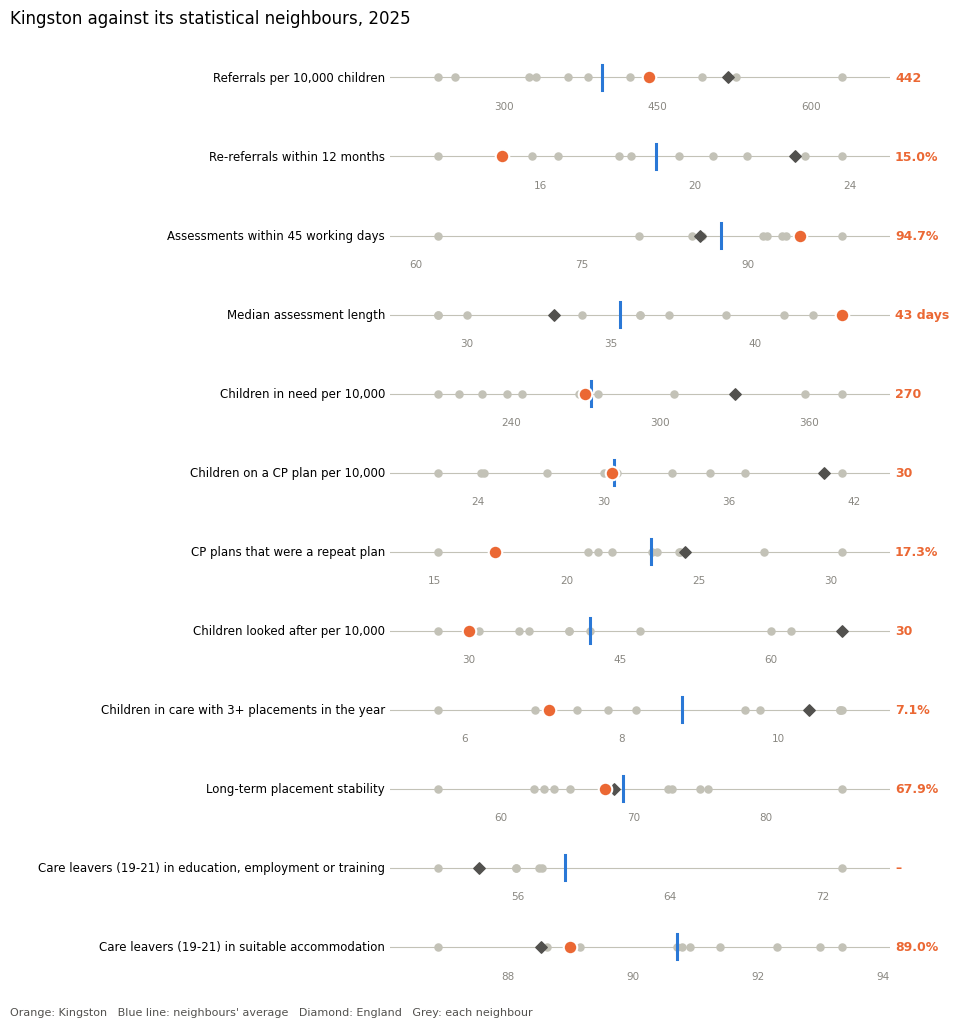

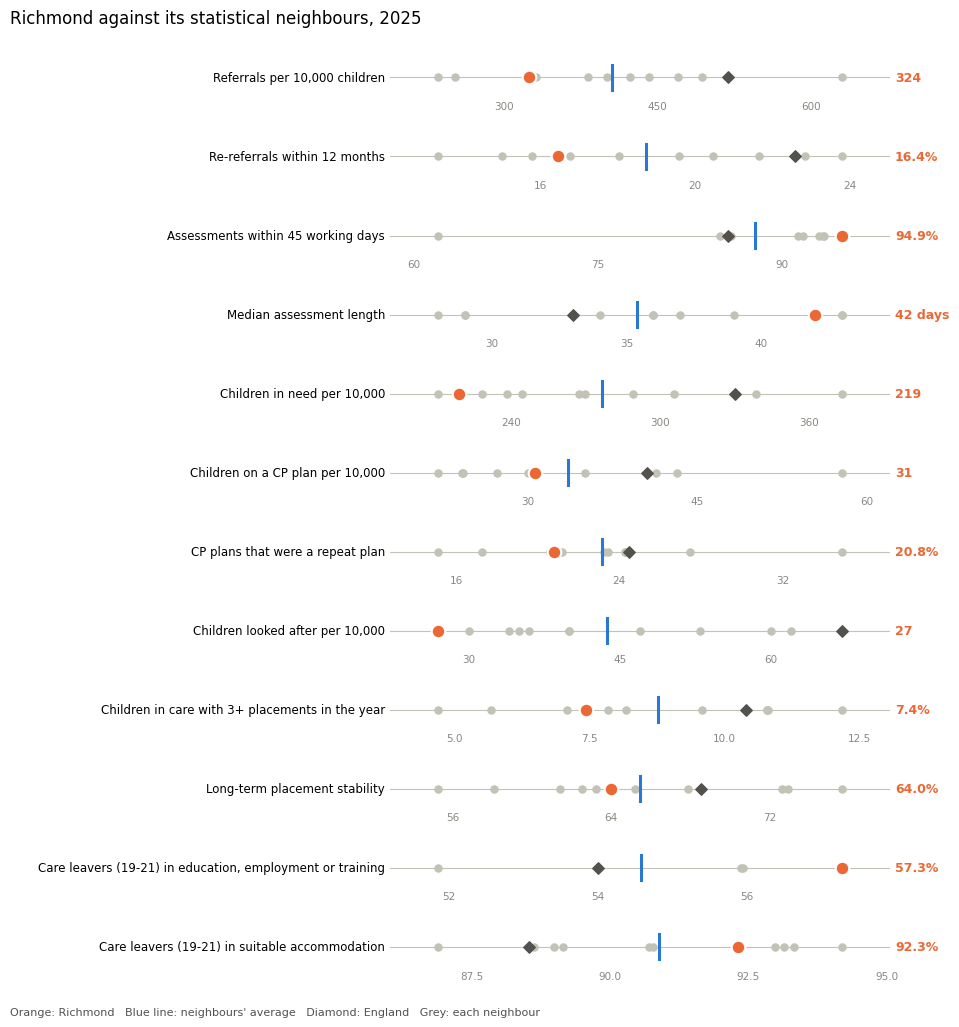

In [ ]:
def strip_chart(t):
    b = bench[bench["target"] == t].reset_index(drop=True)
    fig, axes = plt.subplots(len(b), 1, figsize=(10, 0.78 * len(b) + 0.8))
    for ax, (_, r) in zip(axes, b.iterrows()):
        sn_vals = [get(r.kpi, LATEST, n, "Local authority") for n in NEIGHBOURS[t]]
        pts = [v for v in sn_vals + [r.value, r.england] if pd.notna(v)]
        if not pts:
            ax.axis("off"); continue
        lo, hi = min(pts), max(pts); pad = (hi - lo) * 0.12 or 1
        ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(-1, 1)
        ax.axhline(0, color=C_MUTED, lw=0.8, zorder=0)
        ax.scatter([v for v in sn_vals if pd.notna(v)], [0] * sum(pd.notna(v) for v in sn_vals), s=26, color=C_MUTED, zorder=2, clip_on=False)
        if pd.notna(r.sn_avg): ax.plot([r.sn_avg] * 2, [-0.55, 0.55], color=C_SN, lw=2.2, zorder=3)
        if pd.notna(r.england): ax.scatter([r.england], [0], marker="D", s=34, color=C_ENG, zorder=4, clip_on=False)
        if pd.notna(r.value): ax.scatter([r.value], [0], s=95, color=C_TARGET, edgecolor="white", linewidth=1.5, zorder=5, clip_on=False)
        ax.set_yticks([]); ax.tick_params(axis="x", labelsize=7.5, colors="#898781", length=0, pad=1)
        ax.xaxis.set_major_locator(mtick.MaxNLocator(4))
        for s in ax.spines.values(): s.set_visible(False)
        ax.text(-0.01, 0.5, r.label, transform=ax.transAxes, ha="right", va="center", fontsize=8.5)
        ax.text(1.01, 0.5, fmt(r.value, r.unit), transform=ax.transAxes, ha="left", va="center", fontsize=9, color=C_TARGET, fontweight="bold")
    fig.suptitle(f"{TARGETS[t]} against its statistical neighbours, {LATEST}", x=0.02, ha="left", fontsize=12, y=0.995)
    fig.text(0.02, 0.005, "Orange: " + TARGETS[t] + "   Blue line: neighbours' average   Diamond: England   Grey: each neighbour",
             fontsize=8, color="#52514e")
    plt.subplots_adjust(left=0.40, right=0.90, top=0.95, bottom=0.05, hspace=0.75)
    path = OUT / "repo" / "images" / f"benchmark_{TARGETS[t].lower()}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()

for t in TARGETS:
    strip_chart(t)

### Five-year trends

A single year can mislead. These small multiples show each indicator from 2021, with the borough in orange, its neighbours' average in blue and England in grey.

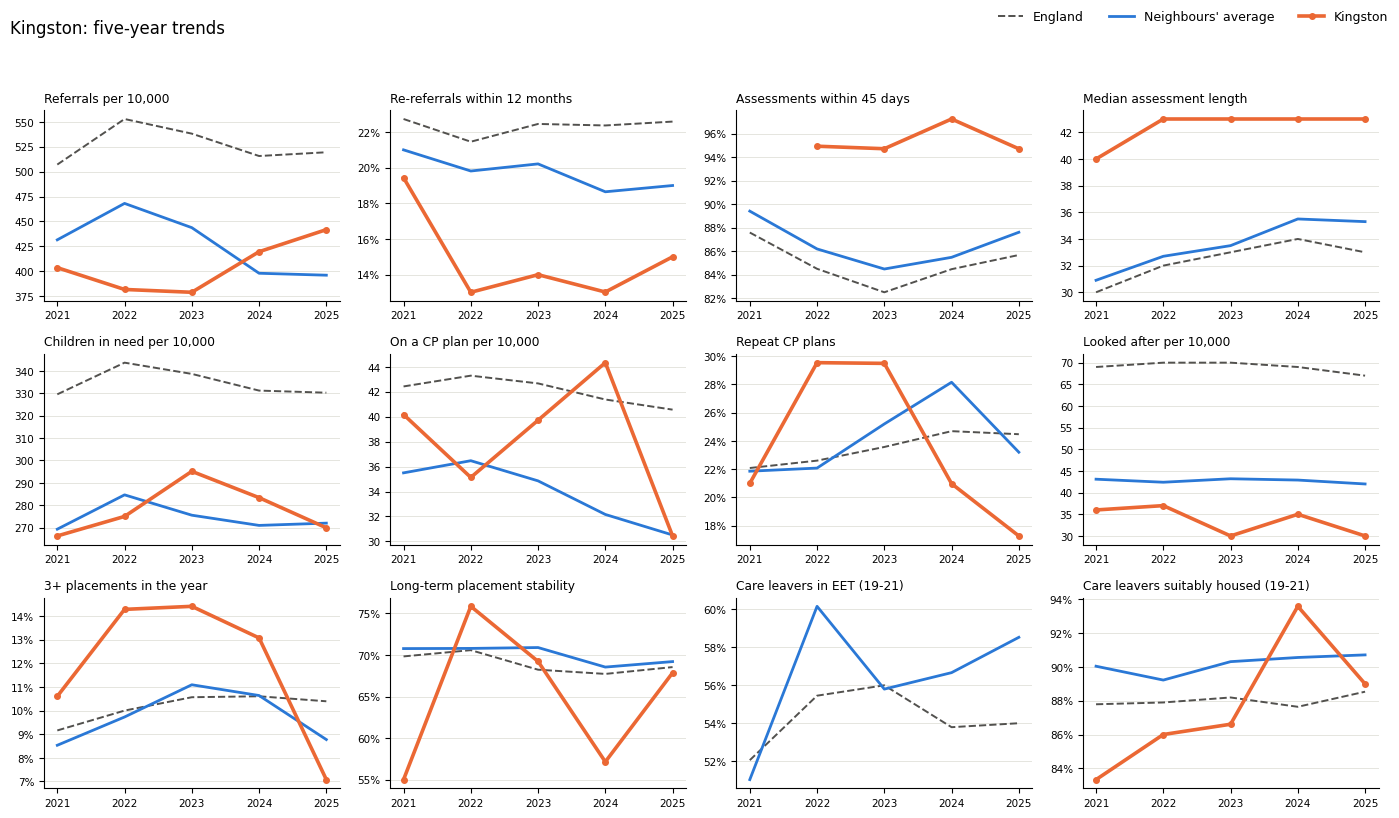

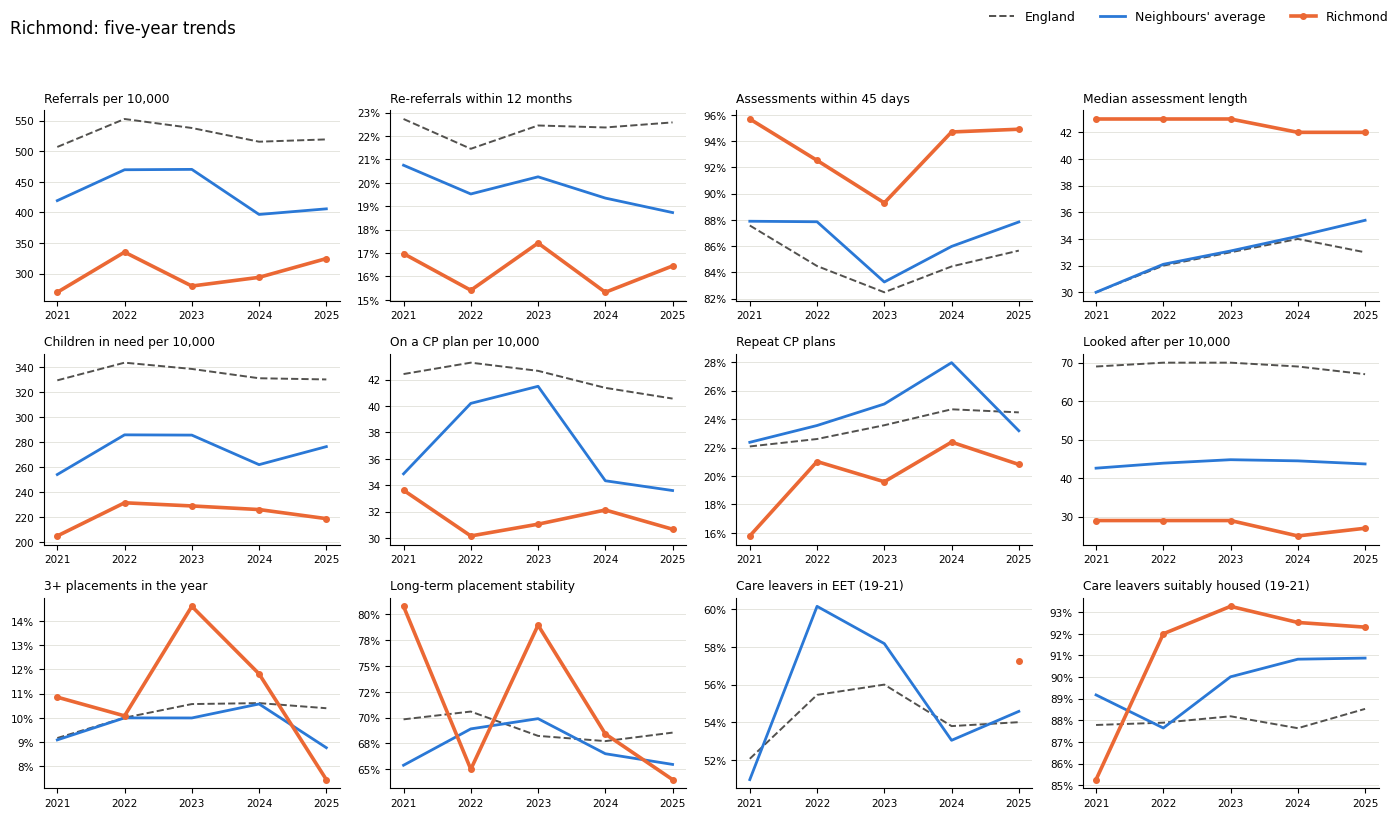

In [ ]:
def trend_chart(t):
    tr = trends[trends["target"] == t]
    fig, axes = plt.subplots(3, 4, figsize=(14, 8.2))
    for ax, (_, k) in zip(axes.flat, KPIS.iterrows()):
        s = tr[tr["kpi"] == k.kpi]
        ax.plot(s["year"], s["england"], color=C_ENG, lw=1.4, ls="--", label="England")
        ax.plot(s["year"], s["sn_avg"], color=C_SN, lw=2, label="Neighbours' average")
        ax.plot(s["year"], s["borough"], color=C_TARGET, lw=2.6, marker="o", ms=4, label=TARGETS[t])
        ax.set_title(k.short, loc="left", fontsize=8.8)
        ax.set_xticks(YEARS); ax.tick_params(labelsize=7.5)
        if k.unit == "%": ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
        ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e1e0d9", lw=0.6)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False, fontsize=9)
    fig.suptitle(f"{TARGETS[t]}: five-year trends", x=0.01, ha="left", fontsize=12)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.savefig(OUT / "repo" / "images" / f"trends_{TARGETS[t].lower()}.png", dpi=140, bbox_inches="tight"); plt.show()

for t in TARGETS:
    trend_chart(t)

### One indicator in detail: assessment timeliness

Bar charts work well when the reader needs exact positions. Here are each borough and its neighbours, ranked, with England marked.

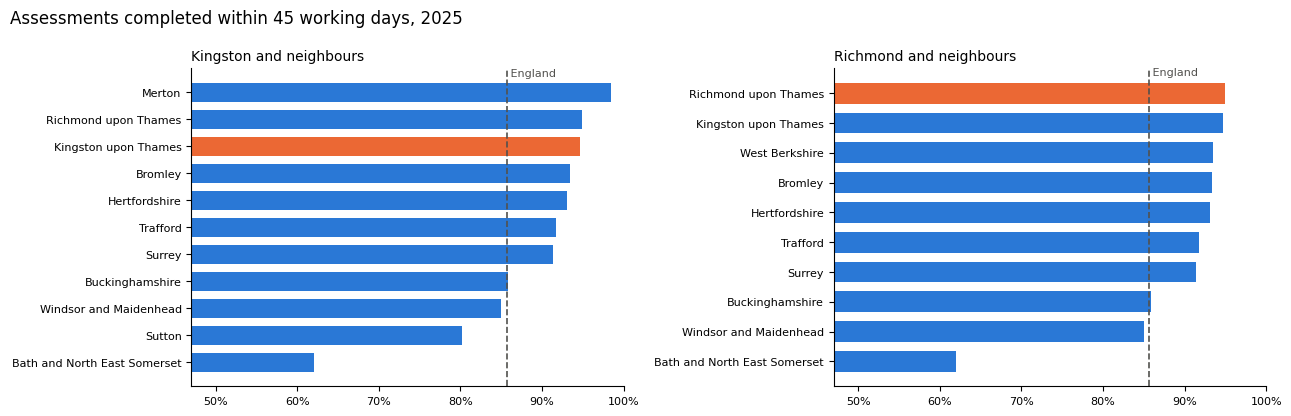

In [ ]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 4.2))
for ax, t in zip(np.atleast_1d(axes), TARGETS):
    names = [t] + NEIGHBOURS[t]
    vals = pd.Series({n: get("assess_45_pct", LATEST, n, "Local authority") for n in names}).dropna().sort_values()
    ax.barh(vals.index, vals.values, color=[C_TARGET if n == t else C_SN for n in vals.index], height=0.7)
    eng_v = get("assess_45_pct", LATEST, "England", "National")
    ax.axvline(eng_v, color=C_ENG, ls="--", lw=1.2); ax.text(eng_v, len(vals) - 0.4, " England", fontsize=8, color=C_ENG)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.tick_params(labelsize=8)
    ax.set_xlim(max(0, vals.min() - 15), 100)
    ax.set_title(f"{TARGETS[t]} and neighbours", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Assessments completed within 45 working days, {LATEST}", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig(OUT / "repo" / "images" / "assessments_neighbours.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Insight brief

Analysts are judged as much on the *so what* as on the numbers. This cell writes a short brief for a non-technical manager. It is generated from the results, so it always matches the data.

* **Strengths** and **areas to explore** use only indicators with a clear direction, ranked by how far the borough sits from its neighbours *relative to how spread out the neighbours are*. That way, a 3-point gap on a tightly clustered measure counts for more than the same gap on a widely spread one.
* Context indicators are described without judgement.

Read it, then edit the wording: the brief is a first draft, and your own interpretation is what an interviewer wants to hear.

In [ ]:
def gap_text(r):
    if pd.isna(r.gap): return "no comparison available"
    if r.unit == "%":
        return f"{abs(r.gap):.1f} percentage points {'above' if r.gap > 0 else 'below'} the neighbour average ({fmt(r.sn_avg, '%')})"
    rel = r.gap / r.sn_avg * 100 if r.sn_avg else np.nan
    return f"{abs(rel):.0f}% {'above' if r.gap > 0 else 'below'} the neighbour average ({fmt(r.sn_avg, r.unit)})"

def brief_for(t):
    b = bench[bench["target"] == t]
    name = TARGETS[t]
    good = b[b["verdict"] == "Better than neighbours"].sort_values("z", ascending=False).head(3)
    bad  = b[b["verdict"] == "Worse than neighbours"].sort_values("z").head(3)
    ctx  = b[b["direction"] == "context"]
    L = [f"### {name}", ""]
    L.append("**Strengths**" if len(good) else "**Strengths:** no indicator is clearly better than neighbours this year.")
    L += [f"* {r.label}: {fmt(r.value, r.unit)}, {gap_text(r)}." for r in good.itertuples()]
    L.append("")
    L.append("**Areas to explore**" if len(bad) else "**Areas to explore:** no indicator is clearly worse than neighbours this year.")
    L += [f"* {r.label}: {fmt(r.value, r.unit)}, {gap_text(r)}. Nationally ranked {int(r.rank)} of {r.of}." for r in bad.itertuples() if pd.notna(r.rank)]
    L.append("")
    L.append("**Demand and context**")
    for r in ctx.itertuples():
        extra = ""
        if pd.notna(r.rank) and r.rank <= 10:   extra = f" Among the 10 lowest in England ({int(r.rank)} of {r.of})."
        elif pd.notna(r.rank) and r.rank > r.of - 10: extra = f" Among the 10 highest in England ({int(r.rank)} of {r.of})."
        L.append(f"* {r.label}: {fmt(r.value, r.unit)} against {fmt(r.sn_avg, r.unit)} for neighbours and {fmt(r.england, r.unit)} for England.{extra}")
    L.append("")
    return "\n".join(L)

brief = "\n".join([
    f"# Insight brief: children's services benchmarking, {LATEST}", "",
    f"*Source: DfE Children in Need and Children Looked After releases, year ending 31 March {LATEST}. "
    "Neighbour averages are simple means of each borough's ten statistical neighbours.*", "",
    *[brief_for(t) for t in TARGETS],
    "### Caveats",
    "* Kingston and Richmond are small authorities, so a few children can move a percentage by several points. Trends matter more than single years.",
    "* Context indicators (rates, median days) describe demand and practice. They are not targets.",
    "* Statistical neighbours are similar on population characteristics, not on how services are organised.",
])
(OUT / "insight_brief.md").write_text(brief, encoding="utf-8")
from IPython.display import Markdown
Markdown(brief)

# Insight brief: children's services benchmarking, 2025

*Source: DfE Children in Need and Children Looked After releases, year ending 31 March 2025. Neighbour averages are simple means of each borough's ten statistical neighbours.*

### Kingston

**Strengths**
* CP plans that were a repeat plan: 17.3%, 5.9 percentage points below the neighbour average (23.2%).
* Re-referrals within 12 months: 15.0%, 4.0 percentage points below the neighbour average (19.0%).
* Assessments within 45 working days: 94.7%, 7.1 percentage points above the neighbour average (87.6%).

**Areas to explore:** no indicator is clearly worse than neighbours this year.

**Demand and context**
* Referrals per 10,000 children: 442 against 396 for neighbours and 519 for England.
* Median assessment length: 43 days against 35 days for neighbours and 33 days for England. Among the 10 highest in England (145 of 153).
* Children in need per 10,000: 270 against 272 for neighbours and 330 for England.
* Children on a CP plan per 10,000: 30 against 31 for neighbours and 41 for England.
* Children looked after per 10,000: 30 against 42 for neighbours and 67 for England. Among the 10 lowest in England (3 of 151).

### Richmond

**Strengths**
* Care leavers (19-21) in education, employment or training: 57.3%, 2.7 percentage points above the neighbour average (54.6%).
* Assessments within 45 working days: 94.9%, 7.1 percentage points above the neighbour average (87.8%).
* Re-referrals within 12 months: 16.4%, 2.3 percentage points below the neighbour average (18.7%).

**Areas to explore:** no indicator is clearly worse than neighbours this year.

**Demand and context**
* Referrals per 10,000 children: 324 against 406 for neighbours and 519 for England.
* Median assessment length: 42 days against 35 days for neighbours and 33 days for England.
* Children in need per 10,000: 219 against 277 for neighbours and 330 for England. Among the 10 lowest in England (6 of 153).
* Children on a CP plan per 10,000: 31 against 34 for neighbours and 41 for England.
* Children looked after per 10,000: 27 against 44 for neighbours and 67 for England. Among the 10 lowest in England (1 of 151).

### Caveats
* Kingston and Richmond are small authorities, so a few children can move a percentage by several points. Trends matter more than single years.
* Context indicators (rates, median days) describe demand and practice. They are not targets.
* Statistical neighbours are similar on population characteristics, not on how services are organised.

## 9. Export

Everything the rest of the project needs is written to `outputs`:

* `outputs/powerbi/`: tidy CSVs for the Power BI report (a *long* fact table of every value, plus lookups)
* `outputs/repo/`: ready for GitHub: the generated `README.md`, `dashboard_data.json` for `index.html`, and the chart images
* `outputs/insight_brief.md`: the plain-English brief

In [ ]:
pb = OUT / "powerbi"
kpi_meta = KPIS.copy()
kpi_meta.to_csv(pb / "dim_kpi.csv", index=False)
values.to_csv(pb / "fact_kpi_values.csv", index=False)

areas = values[["level", "area"]].drop_duplicates()
la_info = rates[rates["level"] == "Local authority"].drop_duplicates("la_name")[["la_name", "region_name", "new_la_code"]]
areas = areas.merge(la_info.rename(columns={"la_name": "area"}), on="area", how="left")
areas.to_csv(pb / "dim_area.csv", index=False)

sn_pairs = pd.DataFrame([(t, n, i + 1) for t, ns in NEIGHBOURS.items() for i, n in enumerate(ns)], columns=["target", "neighbour", "rank"])
sn_pairs.to_csv(pb / "sn_pairs.csv", index=False)
pd.DataFrame([(t, s, REGION[t]) for t, s in TARGETS.items()], columns=["target", "short_name", "region"]).to_csv(pb / "dim_target.csv", index=False)
bench.to_csv(pb / "benchmark_latest.csv", index=False)
trends.to_csv(pb / "benchmark_trends.csv", index=False)

print("Power BI files:")
for f in sorted(pb.glob("*.csv")):
    print(f"  {f.name:<24} {sum(1 for _ in open(f)) - 1:>7,} rows")

Power BI files:
  benchmark_latest.csv          24 rows
  benchmark_trends.csv         120 rows
  dim_area.csv                 167 rows
  dim_kpi.csv                   12 rows
  dim_target.csv                 2 rows
  fact_kpi_values.csv        9,922 rows
  sn_pairs.csv                  20 rows


In [ ]:
def clean(o):
    if isinstance(o, float) and not np.isfinite(o): return None
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else round(float(o), 2)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, list): return [clean(v) for v in o]
    return round(o, 2) if isinstance(o, float) else o

area_set = set(TARGETS) | {n for ns in NEIGHBOURS.values() for n in ns} | set(REGION.values()) | {"England"}
series = {}
for _, k in KPIS.iterrows():
    sub = values[(values["kpi"] == k.kpi) & (values["area"].isin(area_set))]
    series[k.kpi] = {a: {str(int(y)): v for y, v in zip(g["year"], g["value"])} for a, g in sub.groupby("area")}

dash = {
    "meta": {"latest_year": int(LATEST), "years": [int(y) for y in YEARS], "generated": pd.Timestamp.today().strftime("%d %B %Y"),
             "n_las": len(ALL_LAS), "author": "Sara Iqbal"},
    "kpis": KPIS.to_dict(orient="records"),
    "targets": [{"name": t, "short": s, "region": REGION[t], "neighbours": NEIGHBOURS[t]} for t, s in TARGETS.items()],
    "series": series,
    "sn_avg": {t: {k: {str(int(y)): v for y, v in zip(g["year"], g["sn_avg"])} for k, g in trends[trends["target"] == t].groupby("kpi")} for t in TARGETS},
    "latest": bench.drop(columns=["z"]).to_dict(orient="records"),
}
with open(OUT / "repo" / "dashboard_data.json", "w") as f:
    json.dump(clean(dash), f, indent=1)
print("Saved outputs/repo/dashboard_data.json")

Saved outputs/repo/dashboard_data.json


### Generate the README

The README text describing the problem, method and learning is written once below. The results tables and findings are filled in from the data. Review it before publishing: it's your project, so make sure every sentence sounds like you.

In [ ]:
def results_table(t):
    b = bench[bench["target"] == t]
    out = [f"| Indicator | {TARGETS[t]} | Neighbours | {REGION[t]} | England | Verdict |", "| :- | -: | -: | -: | -: | :- |"]
    for r in b.itertuples():
        out.append(f"| {r.label} | {fmt(r.value, r.unit)} | {fmt(r.sn_avg, r.unit)} | {fmt(r.region, r.unit)} | {fmt(r.england, r.unit)} | {r.verdict} |")
    return "\n".join(out)

def headline_points():
    pts = []
    for t in TARGETS:
        b = bench[bench["target"] == t]
        good = b[b["verdict"] == "Better than neighbours"].sort_values("z", ascending=False)
        bad = b[b["verdict"] == "Worse than neighbours"].sort_values("z")
        if len(good):
            r = good.iloc[0]; pts.append(f"* **{TARGETS[t]}'s clearest strength is {r.label.lower()}**: {fmt(r.value, r.unit)}, {gap_text(r)}.")
        if len(bad):
            r = bad.iloc[0]; pts.append(f"* **For {TARGETS[t]}, the indicator most worth a closer look is {r.label.lower()}**: {fmt(r.value, r.unit)}, {gap_text(r)}.")
        cla = b[b["kpi"] == "cla_rate"].iloc[0]
        if pd.notna(cla["rank"]):
            pts.append(f"* {TARGETS[t]} has {fmt(cla['value'], cla['unit'])} children looked after per 10,000, ranking {int(cla['rank'])} of {cla['of']} "
                       f"from lowest in England (England: {fmt(cla['england'], cla['unit'])}).")
    return "\n".join(pts)

sn_lines = "\n".join(f"* **{TARGETS[t]}:** " + ", ".join(NEIGHBOURS[t]) for t in TARGETS)

readme = f'''# How do Kingston and Richmond compare?

**Benchmarking two London boroughs' children's services against their statistical neighbours, London and England, using DfE open data.**

[Live dashboard](https://<your-username>.github.io/<repository-name>/) · [Notebook](benchmarking_statistical_neighbours.ipynb)

![Kingston against its statistical neighbours](images/benchmark_kingston.png)

## The problem

Performance figures mean very little in isolation. If a council completes 80% of its assessments within 45 working days, is that good? It depends entirely on what you compare it with.

Children's services teams answer that question with benchmarking. The Department for Education publishes a list of **statistical neighbours** for every council in England: the ten councils most similar to it on things like deprivation, housing and population. Comparing a council with its neighbours is fairer than comparing it with England as a whole, because like is being compared with like.

I wanted to answer a practical question a performance team would actually be asked: **where do Kingston and Richmond stand, compared with councils like them, and where should a manager look first?**

## How I approached it

Everything runs in one Google Colab notebook.

**1. Load the official data.** I used the DfE's *Children in Need* and *Children Looked After* releases for the year ending 31 March {LATEST}, plus the DfE's statistical neighbour benchmarking tool. Release files change their names from year to year, so the notebook recognises each data set by its **columns** rather than its file name. That makes it reusable when next year's data comes out.

**2. Build twelve indicators for every council in England.** These run from referrals through assessments, child protection and children in care, to care leavers. Where the DfE publishes counts, I recalculated percentages from the counts; for rates, I used the same population estimates the DfE uses. I treated suppressed values (marked `c`, `x`, `z` and so on) as missing, never as zero.

**3. Check the definitions.** Before comparing anything, I checked that my England figures matched the headline figures the DfE publishes. If those don't match, nothing built on them can be trusted.

**4. Benchmark.** For Kingston and Richmond I compared each indicator with the average of their ten statistical neighbours (a simple mean, as in the DfE's LAIT tool), with London and with England. I also ranked each borough among all {len(ALL_LAS)} councils. Each comparison gets a plain verdict: better, worse or in line, or for context measures, simply higher or lower.

**5. Explain it.** The notebook writes an insight brief for a non-technical manager and exports tidy files for a Power BI report and a web dashboard.

## The data

| Source | What I used |
| :- | :- |
| DfE, *Children in need* {LATEST} | Referrals and re-referrals, assessment duration, children in need at 31 March, child protection plans, repeat plans |
| DfE, *Children looked after in England including adoptions* {LATEST} | Rates of children in care, placement stability, care leavers' activity and accommodation |
| DfE, *Children's services statistical neighbour benchmarking tool* (May 2025 update) | The ten statistical neighbours for each borough |

All figures cover {YEARS[0]} to {LATEST}. The statistical neighbours used were:

{sn_lines}

## Results

### Kingston upon Thames, {LATEST}

{results_table("Kingston upon Thames")}

### Richmond upon Thames, {LATEST}

{results_table("Richmond upon Thames")}

"In line" means within 2 percentage points for percentages, or within 10% for rates and days.

### What stands out

{headline_points()}

![Five-year trends for Richmond](images/trends_richmond.png)

The full plain-English findings are in [insight_brief.md](insight_brief.md).

## What I learned, and how I'd interpret this

**The comparison group changes the story.** A figure that looks weak against England can look ordinary against statistical neighbours, and the reverse. Choosing the right comparator is the most important analytical decision in benchmarking, and it's worth explaining every time.

**Not every number is a target.** A low rate of children in care might reflect strong early help, or thresholds set too high. I labelled rates as *context* rather than good or bad, because treating demand measures as targets can push services in the wrong direction.

**Small numbers move a lot.** Both boroughs are small. A handful of children can shift a care leaver percentage by several points, so I always looked at five-year trends and the spread of neighbours before calling anything a strength or a concern.

**Getting the data right is most of the work.** DfE files changed format in {LATEST} (apprenticeships were split out of "training or employment"), some values are suppressed, and file names vary between releases. Building the pipeline to recognise data sets by their structure, and checking the England totals first, is what makes the results trustworthy.

**Benchmarking starts conversations.** The numbers tell a manager *where* to look, not *why*. The next step would always be talking to the teams behind the figures.

## Limitations

* Statistical neighbours match councils on population characteristics, not on how their services are organised.
* The neighbour average is a simple mean, so a very small neighbour counts as much as a very large one.
* Kingston and Richmond share a children's services provider, so differences between them reflect local demand and practice within one organisation.
* The most recent data is for the year ending 31 March {LATEST}.

## Run it yourself

1. Download the two DfE "Download all data" zips and the statistical neighbour workbook (links in the notebook).
2. Open the notebook in Google Colab and select **Runtime > Run all**. Choose the three files when asked.
3. The final cell downloads a zip with the Power BI files, this README, the dashboard data and the charts.

## Tools

Python (pandas, NumPy, Matplotlib), Power BI and DAX, Chart.js, Google Colab, GitHub Pages.

*Built by Sara Iqbal (MSc Data Science) as a portfolio project for data analyst roles in children's services. Contains public sector information licensed under the Open Government Licence v3.0.*
'''
(OUT / "repo" / "README.md").write_text(readme, encoding="utf-8")
shutil.copy(OUT / "insight_brief.md", OUT / "repo" / "insight_brief.md")
print("README written to outputs/repo/README.md")
Markdown(readme)

README written to outputs/repo/README.md


# How do Kingston and Richmond compare?

**Benchmarking two London boroughs' children's services against their statistical neighbours, London and England, using DfE open data.**

[Live dashboard](https://<your-username>.github.io/<repository-name>/) · [Notebook](benchmarking_statistical_neighbours.ipynb)

![Kingston against its statistical neighbours](images/benchmark_kingston.png)

## The problem

Performance figures mean very little in isolation. If a council completes 80% of its assessments within 45 working days, is that good? It depends entirely on what you compare it with.

Children's services teams answer that question with benchmarking. The Department for Education publishes a list of **statistical neighbours** for every council in England: the ten councils most similar to it on things like deprivation, housing and population. Comparing a council with its neighbours is fairer than comparing it with England as a whole, because like is being compared with like.

I wanted to answer a practical question a performance team would actually be asked: **where do Kingston and Richmond stand, compared with councils like them, and where should a manager look first?**

## How I approached it

Everything runs in one Google Colab notebook.

**1. Load the official data.** I used the DfE's *Children in Need* and *Children Looked After* releases for the year ending 31 March 2025, plus the DfE's statistical neighbour benchmarking tool. Release files change their names from year to year, so the notebook recognises each data set by its **columns** rather than its file name. That makes it reusable when next year's data comes out.

**2. Build twelve indicators for every council in England.** These run from referrals through assessments, child protection and children in care, to care leavers. Where the DfE publishes counts, I recalculated percentages from the counts; for rates, I used the same population estimates the DfE uses. I treated suppressed values (marked `c`, `x`, `z` and so on) as missing, never as zero.

**3. Check the definitions.** Before comparing anything, I checked that my England figures matched the headline figures the DfE publishes. If those don't match, nothing built on them can be trusted.

**4. Benchmark.** For Kingston and Richmond I compared each indicator with the average of their ten statistical neighbours (a simple mean, as in the DfE's LAIT tool), with London and with England. I also ranked each borough among all 155 councils. Each comparison gets a plain verdict: better, worse or in line, or for context measures, simply higher or lower.

**5. Explain it.** The notebook writes an insight brief for a non-technical manager and exports tidy files for a Power BI report and a web dashboard.

## The data

| Source | What I used |
| :- | :- |
| DfE, *Children in need* 2025 | Referrals and re-referrals, assessment duration, children in need at 31 March, child protection plans, repeat plans |
| DfE, *Children looked after in England including adoptions* 2025 | Rates of children in care, placement stability, care leavers' activity and accommodation |
| DfE, *Children's services statistical neighbour benchmarking tool* (May 2025 update) | The ten statistical neighbours for each borough |

All figures cover 2021 to 2025. The statistical neighbours used were:

* **Kingston:** Sutton, Merton, Hertfordshire, Bromley, Bath and North East Somerset, Windsor and Maidenhead, Trafford, Richmond upon Thames, Surrey, Buckinghamshire
* **Richmond:** Windsor and Maidenhead, Kingston upon Thames, Surrey, Wokingham, Bromley, Trafford, Buckinghamshire, Hertfordshire, Bath and North East Somerset, West Berkshire

## Results

### Kingston upon Thames, 2025

| Indicator | Kingston | Neighbours | Outer London | England | Verdict |
| :- | -: | -: | -: | -: | :- |
| Referrals per 10,000 children | 442 | 396 | 525 | 519 | Higher than neighbours |
| Re-referrals within 12 months | 15.0% | 19.0% | 19.6% | 22.6% | Better than neighbours |
| Assessments within 45 working days | 94.7% | 87.6% | 87.2% | 85.7% | Better than neighbours |
| Median assessment length | 43 days | 35 days | 32 days | 33 days | Higher than neighbours |
| Children in need per 10,000 | 270 | 272 | 327 | 330 | In line with neighbours |
| Children on a CP plan per 10,000 | 30 | 31 | 38 | 41 | In line with neighbours |
| CP plans that were a repeat plan | 17.3% | 23.2% | 19.3% | 24.5% | Better than neighbours |
| Children looked after per 10,000 | 30 | 42 | 43 | 67 | Lower than neighbours |
| Children in care with 3+ placements in the year | 7.1% | 8.8% | 10.4% | 10.4% | In line with neighbours |
| Long-term placement stability | 67.9% | 69.2% | 68.1% | 68.5% | In line with neighbours |
| Care leavers (19-21) in education, employment or training | – | 58.5% | 55.1% | 54.0% | No comparison |
| Care leavers (19-21) in suitable accommodation | 89.0% | 90.7% | 88.0% | 88.5% | In line with neighbours |

### Richmond upon Thames, 2025

| Indicator | Richmond | Neighbours | Outer London | England | Verdict |
| :- | -: | -: | -: | -: | :- |
| Referrals per 10,000 children | 324 | 406 | 525 | 519 | Lower than neighbours |
| Re-referrals within 12 months | 16.4% | 18.7% | 19.6% | 22.6% | Better than neighbours |
| Assessments within 45 working days | 94.9% | 87.8% | 87.2% | 85.7% | Better than neighbours |
| Median assessment length | 42 days | 35 days | 32 days | 33 days | Higher than neighbours |
| Children in need per 10,000 | 219 | 277 | 327 | 330 | Lower than neighbours |
| Children on a CP plan per 10,000 | 31 | 34 | 38 | 41 | In line with neighbours |
| CP plans that were a repeat plan | 20.8% | 23.2% | 19.3% | 24.5% | Better than neighbours |
| Children looked after per 10,000 | 27 | 44 | 43 | 67 | Lower than neighbours |
| Children in care with 3+ placements in the year | 7.4% | 8.8% | 10.4% | 10.4% | In line with neighbours |
| Long-term placement stability | 64.0% | 65.5% | 68.1% | 68.5% | In line with neighbours |
| Care leavers (19-21) in education, employment or training | 57.3% | 54.6% | 55.1% | 54.0% | Better than neighbours |
| Care leavers (19-21) in suitable accommodation | 92.3% | 90.9% | 88.0% | 88.5% | In line with neighbours |

"In line" means within 2 percentage points for percentages, or within 10% for rates and days.

### What stands out

* **Kingston's clearest strength is cp plans that were a repeat plan**: 17.3%, 5.9 percentage points below the neighbour average (23.2%).
* Kingston has 30 children looked after per 10,000, ranking 3 of 151 from lowest in England (England: 67).
* **Richmond's clearest strength is care leavers (19-21) in education, employment or training**: 57.3%, 2.7 percentage points above the neighbour average (54.6%).
* Richmond has 27 children looked after per 10,000, ranking 1 of 151 from lowest in England (England: 67).

![Five-year trends for Richmond](images/trends_richmond.png)

The full plain-English findings are in [insight_brief.md](insight_brief.md).

## What I learned, and how I'd interpret this

**The comparison group changes the story.** A figure that looks weak against England can look ordinary against statistical neighbours, and the reverse. Choosing the right comparator is the most important analytical decision in benchmarking, and it's worth explaining every time.

**Not every number is a target.** A low rate of children in care might reflect strong early help, or thresholds set too high. I labelled rates as *context* rather than good or bad, because treating demand measures as targets can push services in the wrong direction.

**Small numbers move a lot.** Both boroughs are small. A handful of children can shift a care leaver percentage by several points, so I always looked at five-year trends and the spread of neighbours before calling anything a strength or a concern.

**Getting the data right is most of the work.** DfE files changed format in 2025 (apprenticeships were split out of "training or employment"), some values are suppressed, and file names vary between releases. Building the pipeline to recognise data sets by their structure, and checking the England totals first, is what makes the results trustworthy.

**Benchmarking starts conversations.** The numbers tell a manager *where* to look, not *why*. The next step would always be talking to the teams behind the figures.

## Limitations

* Statistical neighbours match councils on population characteristics, not on how their services are organised.
* The neighbour average is a simple mean, so a very small neighbour counts as much as a very large one.
* Kingston and Richmond share a children's services provider, so differences between them reflect local demand and practice within one organisation.
* The most recent data is for the year ending 31 March 2025.

## Run it yourself

1. Download the two DfE "Download all data" zips and the statistical neighbour workbook (links in the notebook).
2. Open the notebook in Google Colab and select **Runtime > Run all**. Choose the three files when asked.
3. The final cell downloads a zip with the Power BI files, this README, the dashboard data and the charts.

## Tools

Python (pandas, NumPy, Matplotlib), Power BI and DAX, Chart.js, Google Colab, GitHub Pages.

*Built by Sara Iqbal (MSc Data Science) as a portfolio project for data analyst roles in children's services. Contains public sector information licensed under the Open Government Licence v3.0.*


### Download everything (Colab)

In [ ]:
shutil.make_archive("benchmarking_outputs", "zip", OUT)
if IN_COLAB:
    colab_files.download("benchmarking_outputs.zip")
else:
    print("Saved benchmarking_outputs.zip next to this notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What next

* **Add education measures.** Persistent absence and EHCP timeliness from the same DfE service would round out the picture for a children's services organisation that also runs education.
* **Rerun next year.** When the 2026 releases are published, download the new zips and run the notebook again. The file detection means no code changes should be needed.
* **Test whether gaps are meaningful.** With small numbers, a confidence interval around each percentage would show which differences are likely to be real.